# Router A/B evaluation - V1 (WhatsApp)

## Section 1 : Prepare Data set

In [12]:
import json, re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200)

ROOT = Path.cwd()
if not (ROOT/"eval-data").exists() and (ROOT.parent/"eval-data").exists(): ROOT = ROOT.parent
EVAL = ROOT/"eval-data"
LOGS = ROOT/"test_data"/"router_runs_2026-09-19_2026-09-21.json"
BRANDS = ROOT/"brands_level_ai_info.json"

def canon(x):
    if not isinstance(x, str): return x
    return re.sub(r"^ShoppingAgentV\d+$", "ShoppingAgent", x.strip())
def is_malformed(x):
    if not isinstance(x, str): return True
    x = x.strip(); return x == "" or "\n" in x or len(x) > 60
def top_prob(js):
    try:
        p = json.loads(js) if isinstance(js, str) else js
        return max(p.values()) if p else np.nan
    except Exception: return np.nan

# silver (LLM) + logs (latency/cost) + brand agent sets
ds = json.load(open(EVAL/"routing_dataset.json", encoding="utf-8"))["routing_dataset"]
df = pd.DataFrame([{"id": r["id"], "sender": r["sender"], "brand": r["brand"], "turn_index": r["turn_index"],
                    "current_message": r["current_message"], "previous_agent": r["previous_agent"],
                    "silver_raw": r["LLM_OUTPUT"]} for r in ds])
logs = json.load(open(LOGS, encoding="utf-8"))
df = df.merge(pd.DataFrame([{"id": r["id"], "llm_latency": r.get("latency_s"), "llm_cost": r.get("total_cost")}
                            for r in logs]), on="id", how="left")
brand_agents = {b["brand"]: set(canon(a["agentName"]) for a in b["agentsInfo"])
                for b in json.load(open(BRANDS, encoding="utf-8"))}

# result arms
ARM_SPECS = [("Jev", "Jev-classification-result.csv", "jev_output", "probabilities"),
             ("Laya-multilingual", "Laya-multilingual-result.csv", "laya_output", "distribution"),
             ("Laya-typed", "Laya-typed-decisions-result.csv", "laya_output", "distribution")]
ARMS = []
for name, fname, outc, probc in ARM_SPECS:
    p = EVAL/fname
    if not p.exists(): print("MISSING:", fname); continue
    d = pd.read_csv(p)
    keep = ["id", outc, "confidence", "response_time", probc] + (["input_tokens"] if "input_tokens" in d.columns else [])
    d = d[keep].rename(columns={outc: f"{name}__out", "confidence": f"{name}__conf", "response_time": f"{name}__rt",
                                probc: f"{name}__prob", "input_tokens": f"{name}__intok"})
    df = df.merge(d, on="id", how="left"); ARMS.append(name)

# normalize (canon) + scoring set + agree flags
df["silver"] = df["silver_raw"].map(canon)
for name in ARMS:
    df[f"{name}__out_c"] = df[f"{name}__out"].map(canon)
    df[f"{name}__conf"] = pd.to_numeric(df[f"{name}__conf"], errors="coerce")
    df[f"{name}__rt"] = pd.to_numeric(df[f"{name}__rt"], errors="coerce")
    df[f"{name}__agree"] = df[f"{name}__out_c"] == df["silver"]
df["silver_malformed"] = df["silver_raw"].map(is_malformed)
df["silver_routable"] = df.apply(lambda r: isinstance(r["silver"], str) and r["silver"] in brand_agents.get(r["brand"], set()), axis=1)
df["scored"] = (~df["silver_malformed"]) & (df["silver_routable"])
scored = df[df["scored"]].copy()
COLORS = {"Jev": "#4C78A8", "Laya-multilingual": "#F58518", "Laya-typed": "#54A24B"}

print("arms:", ARMS)
print(f"total {len(df)} | malformed silver {int(df['silver_malformed'].sum())} | "
      f"non-routable {int((~df['silver_routable'] & ~df['silver_malformed']).sum())} | SCORED {int(df['scored'].sum())}")

arms: ['Jev', 'Laya-multilingual', 'Laya-typed']
total 9747 | malformed silver 7 | non-routable 20 | SCORED 9720


## Section 2 : Calculate Agreement 

- Agreement score =   correct output count ÷ Total output count



Jev                  79.13
Laya-typed           64.88
Laya-multilingual    51.43
dtype: float64


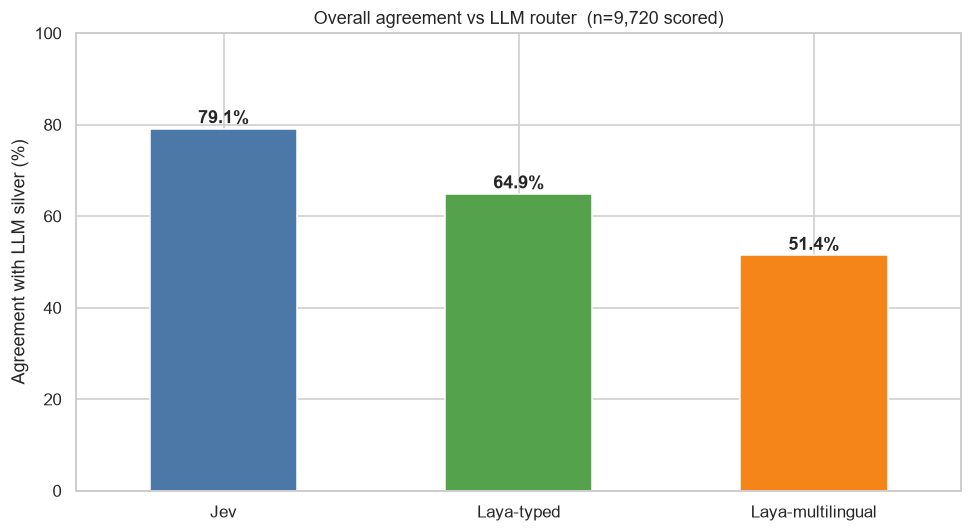

In [20]:
# Cell 2 — Overall agreement with LLM silver
ov = pd.Series({name: scored[f"{name}__agree"].mean() * 100 for name in ARMS}).sort_values(ascending=False)
print(ov.round(2))

ax = ov.plot(kind="bar", color=[COLORS[k] for k in ov.index])
ax.set_ylabel("Agreement with LLM silver (%)"); ax.set_ylim(0, 100)
ax.set_title(f"Overall agreement vs LLM router  (n={len(scored):,} scored)")
for i, v in enumerate(ov):
    ax.text(i, v + 1.2, f"{v:.1f}%", ha="center", fontweight="bold")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### Section 2.2 : Calculate Agreement in each class intervals (0–10, 10–20, … 90–100) 


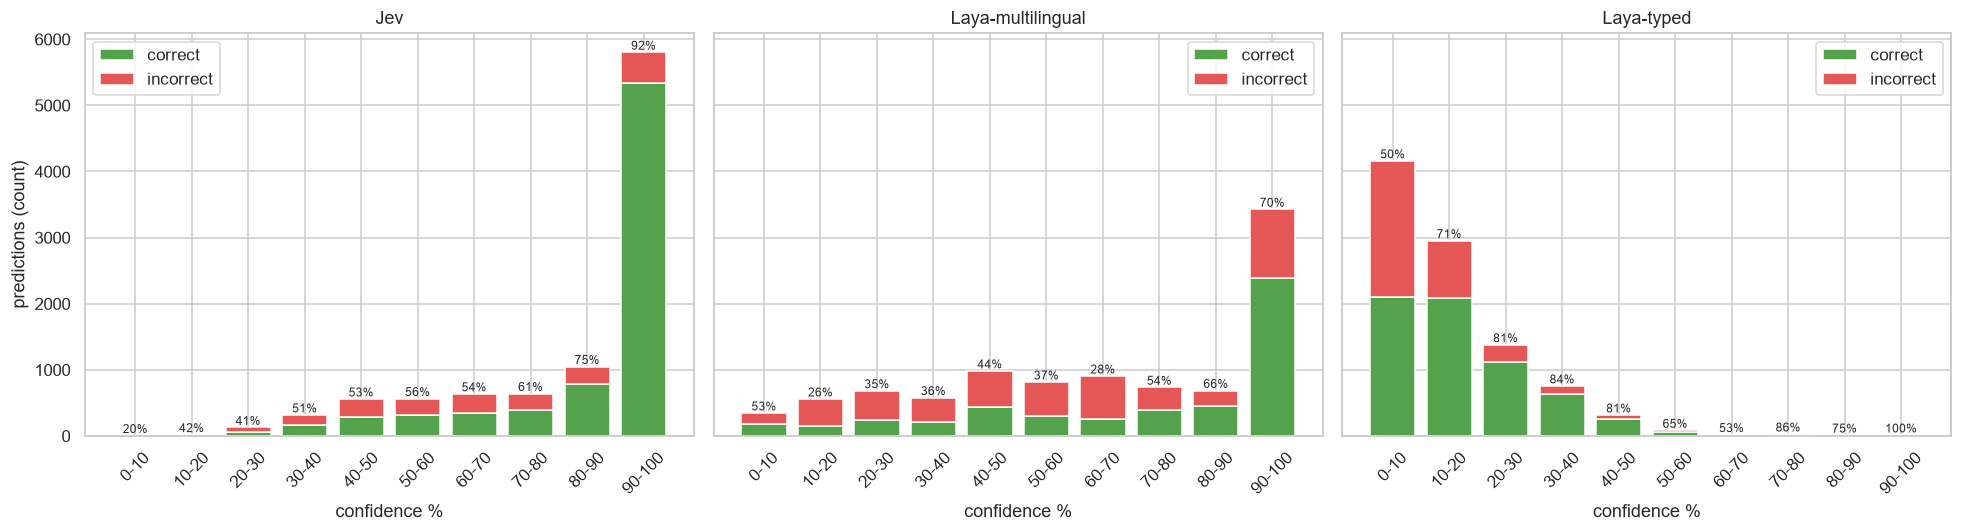


=== Jev ===
        kept  correct  agree_%
bin                           
0-10       5        1     20.0
10-20     19        8     42.1
20-30    128       53     41.4
30-40    317      163     51.4
40-50    558      293     52.5
50-60    564      316     56.0
60-70    636      343     53.9
70-80    641      388     60.5
80-90   1049      791     75.4
90-100  5803     5335     91.9

=== Laya-multilingual ===
        kept  correct  agree_%
bin                           
0-10     346      184     53.2
10-20    558      145     26.0
20-30    683      237     34.7
30-40    579      206     35.6
40-50    984      433     44.0
50-60    814      301     37.0
60-70    906      257     28.4
70-80    735      395     53.7
80-90    687      456     66.4
90-100  3428     2385     69.6

=== Laya-typed ===
        kept  correct  agree_%
bin                           
0-10    4160     2097     50.4
10-20   2953     2089     70.7
20-30   1379     1116     80.9
30-40    756      637     84.3
40-50    3

In [22]:
# Cell 2b — correctness by confidence class-interval
bins = list(range(0, 101, 10))
labels = [f"{b}-{b+10}" for b in bins[:-1]]
fig, axes = plt.subplots(1, len(ARMS), figsize=(6*len(ARMS), 5), sharey=True)
if len(ARMS) == 1: axes = [axes]
for ax, name in zip(axes, ARMS):
    s = scored.dropna(subset=[f"{name}__conf"]).copy()
    s["bin"] = pd.cut(s[f"{name}__conf"]*100, bins=bins, labels=labels, include_lowest=True)
    grp = s.groupby("bin", observed=False)
    total = grp.size(); correct = grp[f"{name}__agree"].sum(); incorrect = total - correct
    ax.bar(labels, correct, label="correct", color="#54A24B")
    ax.bar(labels, incorrect, bottom=correct, label="incorrect", color="#E45756")
    for i, (c, t) in enumerate(zip(correct, total)):
        if t: ax.text(i, t, f"{c/t*100:.0f}%", ha="center", va="bottom", fontsize=8)
    ax.set_title(name); ax.set_xlabel("confidence %"); ax.tick_params(axis="x", rotation=45); ax.legend()
axes[0].set_ylabel("predictions (count)")
plt.tight_layout(); plt.show()

for name in ARMS:
    s = scored.dropna(subset=[f"{name}__conf"]).copy()
    s["bin"] = pd.cut(s[f"{name}__conf"]*100, bins=bins, labels=labels, include_lowest=True)
    t = s.groupby("bin", observed=False).agg(kept=(f"{name}__agree", "size"), correct=(f"{name}__agree", "sum"))
    t["agree_%"] = (t["correct"] / t["kept"] * 100).round(1)
    print(f"\n=== {name} ===\n{t}")

### Section 2.3: confidence >= 70% band

                   kept  coverage_%  correct  agree_of_kept_%  correct_of_total_%
model                                                                            
Jev                7548        77.7     6549             86.8                67.4
Laya-multilingual  4851        49.9     3236             66.7                33.3
Laya-typed           53         0.5       46             86.8                 0.5


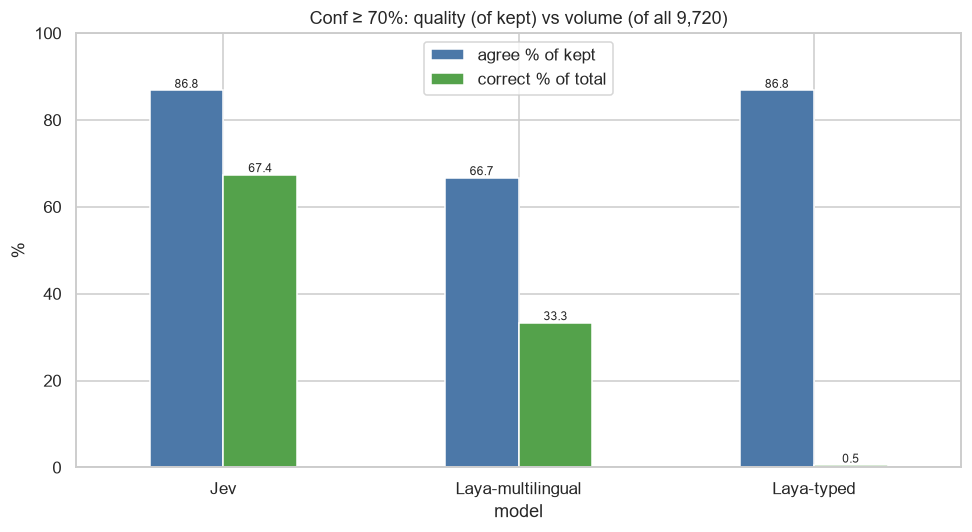

In [18]:
# Cell 2c — confidence >= 70% band (precision AND share of total)
rows = []
for name in ARMS:
    s = scored.dropna(subset=[f"{name}__conf"])
    hi = s[s[f"{name}__conf"] >= 0.70]
    kept = len(hi); correct = int(hi[f"{name}__agree"].sum())
    rows.append({"model": name, "kept": kept, "coverage_%": round(100*kept/len(scored), 1),
                 "correct": correct,
                 "agree_of_kept_%": round(100*correct/kept, 1) if kept else 0,
                 "correct_of_total_%": round(100*correct/len(scored), 1)})
t = pd.DataFrame(rows).set_index("model"); print(t)

ax = t[["agree_of_kept_%", "correct_of_total_%"]].plot(kind="bar", color=["#4C78A8", "#54A24B"])
ax.set_ylim(0, 100); ax.set_ylabel("%")
ax.set_title("Conf ≥ 70%: quality (of kept) vs volume (of all 9,720)")
ax.legend(["agree % of kept", "correct % of total"])
for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=8)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

 ## Section 3: Per-brand agreement

                      n   Jev  Laya-multilingual  Laya-typed
brand                                                       
zop                3955  78.0               50.2        67.1
nutrabox           1037  87.2               60.9        75.7
tbof               1004  76.1               50.1        46.2
afora               696  85.6               51.9        75.4
trickortreatfoods   613  77.0               63.5        63.3
soulflower          324  78.4               62.7        58.0
wheelseyesgtn       308  92.5               32.1        91.9
tramoraindia        300  80.7               47.0        64.0
mazikien            212  71.7               43.9        38.2
callmate            209  74.6               30.1        60.8

Overall (per-message)        : {'Jev': np.float64(79.1), 'Laya-multilingual': np.float64(51.4), 'Laya-typed': np.float64(64.9)}
Per-brand average (equal wt) : {'Jev': np.float64(77.6), 'Laya-multilingual': np.float64(51.5), 'Laya-typed': np.float64(65.0)}


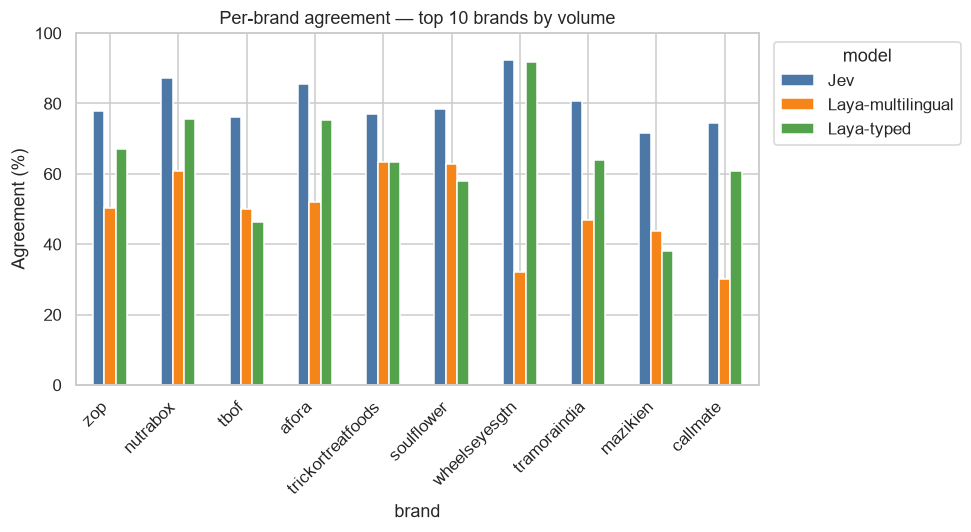

In [19]:
# Cell 3 — Per-brand agreement (top 10 brands)
top = scored["brand"].value_counts().head(10).index.tolist()
rows = []
for b in top:
    sub = scored[scored["brand"] == b]
    row = {"brand": b, "n": len(sub)}
    for name in ARMS:
        row[name] = round(sub[f"{name}__agree"].mean() * 100, 1)
    rows.append(row)
pb = pd.DataFrame(rows).set_index("brand")
print(pb)

overall = {name: round(scored[f"{name}__agree"].mean() * 100, 1) for name in ARMS}
per_brand_avg = {name: round(scored.groupby("brand")[f"{name}__agree"].mean().mean() * 100, 1) for name in ARMS}
print("\nOverall (per-message)        :", overall)
print("Per-brand average (equal wt) :", per_brand_avg)

ax = pb[ARMS].plot(kind="bar", color=[COLORS[k] for k in ARMS])
ax.set_ylabel("Agreement (%)"); ax.set_ylim(0, 100)
ax.set_title("Per-brand agreement — top 10 brands by volume")
ax.legend(title="model", bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

- Jev isn't just higher on average, it's consistent across brands, which is the property a multi-tenant router needs. Laya-typed's average is decent but too brand-dependent to trust uniformly.